# Recapture: what a screen does to an image

Dev pairs only; the test attacks are not opened. The ranges in `configs/synth.yaml` come from here, then widened.

Needs `screenpad splits`, `screenpad cache` and `screenpad synth --splits dev --variants 5 --set synth.camera_only_frac=1.0`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from screenpad.config import load_config
from screenpad.utils import limit_threads
from screenpad.data.io import load_image
from screenpad.data.cache import load_cache, cache_frame
from screenpad.data.preprocess import FaceCropper
from screenpad.eda.pairs import register, warp_to_bona, tone_curves, grid_peak
from screenpad.eda.stats import pixel_stats_frame
from screenpad.synth.recapture import RecaptureParams, _display, render_screen, camera, linear_to_srgb
from screenpad.synth.generate import simulate, CAMERA_ONLY

limit_threads(6)
cfg = load_config()
SEED = int(cfg.seed)
ROOT = Path(cfg.data.root)
RANGES = cfg.synth.ranges

BONAFIDE_C, CAMONLY_C, ATTACK_C, SYNTH_C = "#2a78d6", "#8fb8e8", "#eb6834", "#a8431a"
INK_2, GRID, SURFACE = "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "figure.dpi": 110,
})

splits = pd.read_csv(cfg.data.splits, dtype={"id": str})
dev = splits[splits.split == "dev"]
DEV_IDS = sorted(dev.id.unique())
phone = dev[dev.label == 1].set_index("id").exif_model
pairs = {i: (np.asarray(load_image(ROOT / f"Bonafide/{i}.png")), np.asarray(load_image(ROOT / f"Screens/{i}.png"))) for i in DEV_IDS}

## 1. Geometry (SIFT + RANSAC homography to the twin)

In [2]:
rows, H = [], {}
fc = FaceCropper()
for i, (b, a) in pairs.items():
    H[i], inl = register(b, a)
    Hi = np.linalg.inv(H[i])
    c = cv2.perspectiveTransform(np.float32([[[0, 0], [1023, 0], [1023, 1023], [0, 1023]]]), Hi)[0]
    sides = np.linalg.norm(np.roll(c, -1, 0) - c, axis=1)
    rows.append({"id": i, "phone": phone[i], "attack size": f"{a.shape[1]}x{a.shape[0]}", "inliers": inl,
                 "camera px per source px": sides.mean() / 1024,
                 "keystone (max/min side)": sides.max() / sides.min()})
geo = pd.DataFrame(rows).set_index("id")
display(geo.round(2))

[ WARN:0@1.446] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


,phone,attack size,inliers,camera px per source px,keystone (max/min side)
id,,,,,
00998,iPhone 15,2637x2564,463,2.53,1.06
10673,iPhone 15,2891x2803,2927,2.79,1.02
10741,iPhone 15,2784x3013,2816,2.99,1.01
10881,SM-A127F,2446x2389,1380,2.31,1.02
10889,SM-A127F,1980x2358,132,2.44,1.17
10960,SM-A127F,2650x2670,571,2.57,1.01


2.3-3.0 camera px per source px. Mild tilt (keystone 1-17%).

## 2. Native-resolution patches

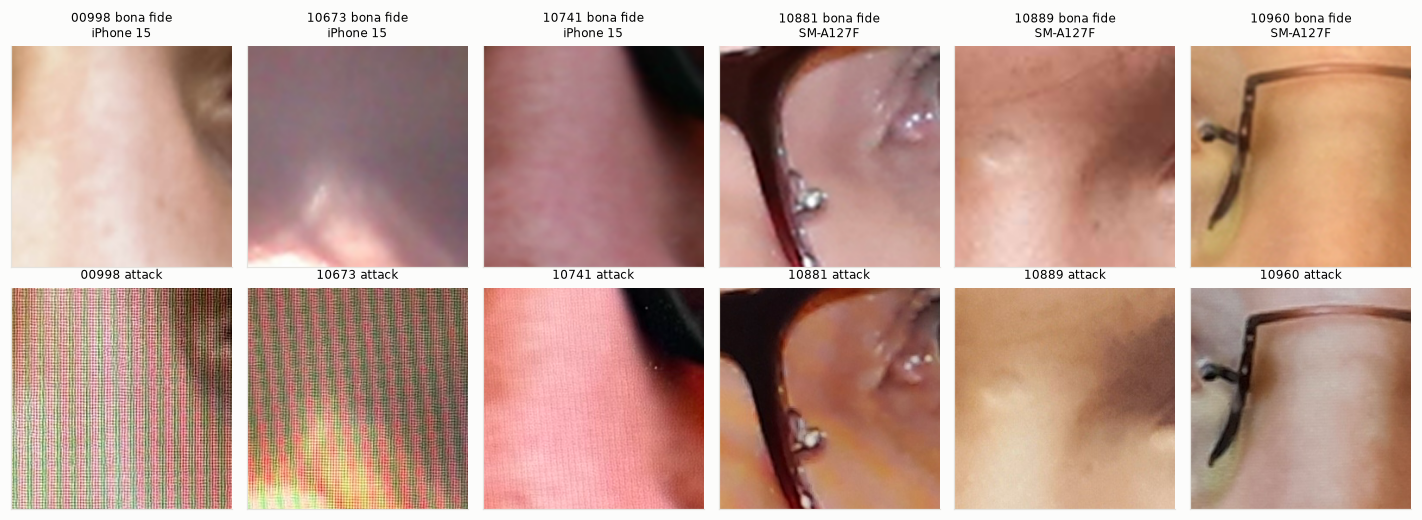

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for k, i in enumerate(DEV_IDS):
    b, a = pairs[i]
    det = fc.detect(a)
    x, y, w, h = det.box
    cx, cy = int(x + w / 2), int(y + h * 0.4)
    pa = a[cy - 128:cy + 128, cx - 128:cx + 128]
    bx, by = cv2.perspectiveTransform(np.float32([[[cx, cy]]]), H[i])[0, 0]
    half = int(128 / geo.loc[i, "camera px per source px"])
    pb = cv2.resize(b[int(by) - half:int(by) + half, int(bx) - half:int(bx) + half], (256, 256), interpolation=cv2.INTER_CUBIC)
    for r, (im, lab) in enumerate(((pb, "bona fide"), (pa, "attack"))):
        axes[r, k].imshow(im); axes[r, k].set_xticks([]); axes[r, k].set_yticks([]); axes[r, k].grid(False)
        axes[r, k].set_title(f"{i} {lab}" + (f"\n{phone[i]}" if r == 0 else ""), fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
peaks = []
for i in DEV_IDS:
    a = pairs[i][1]
    x, y, w, h = fc.detect(a).box
    peaks.append({"id": i, "phone": phone[i], **grid_peak(a, (int(x + w / 2), int(y + h / 2)))})
peaks = pd.DataFrame(peaks).set_index("id")
display(peaks.round(3))

,phone,fx,fy,period_px,excess_log10
id,,,,,
00998,iPhone 15,-0.295,-0.002,3.391,5.945
10673,iPhone 15,-0.301,-0.006,3.324,5.687
10741,iPhone 15,0.143,-0.014,6.982,4.448
10881,SM-A127F,0.070,-0.023,13.492,3.946
10889,SM-A127F,-0.500,0.000,2.000,4.005
10960,SM-A127F,0.006,0.273,3.656,4.434


One dominant periodic peak per attack: the LCD stripe grid (about 3.3 px) on the iPhone, weaker or aliased into moiré on the Samsung. Roughly 0.4-0.8 screen px per source px.

## 3. Tone and colour

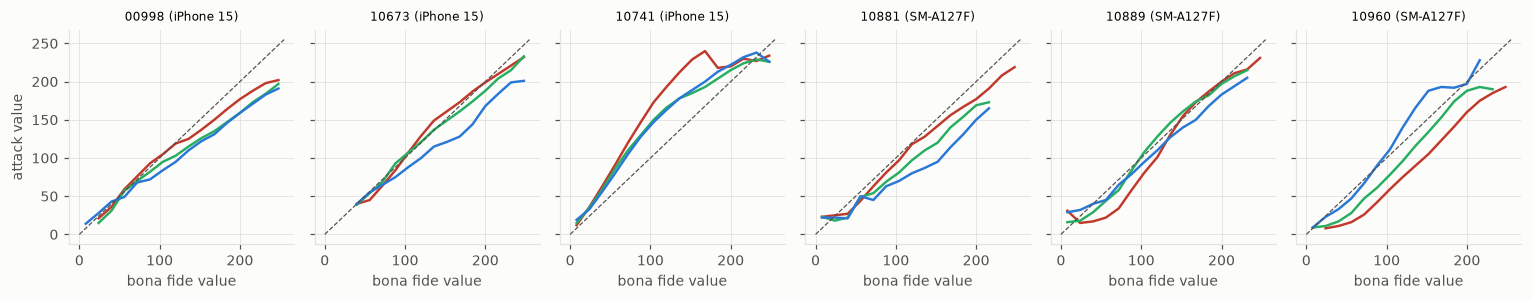

In [5]:
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8), sharey=True)
xs = np.arange(0, 256, 16) + 8
for ax, i in zip(axes, DEV_IDS):
    b, a = pairs[i]
    curves = tone_curves(b, warp_to_bona(a, H[i], (b.shape[1], b.shape[0])))
    for c, col in zip(curves, ("#c0392b", "#27ae60", "#2a78d6")):
        ax.plot(xs, c, color=col, lw=1.6)
    ax.plot([0, 255], [0, 255], color=INK_2, lw=0.8, ls="--")
    ax.set_title(f"{i} ({phone[i]})", fontsize=8); ax.set_xlabel("bona fide value")
axes[0].set_ylabel("attack value")
plt.tight_layout(); plt.show()

Different for every pair, in both directions, so the simulator randomises it.

## 4. After the face crop

In [6]:
real = load_cache(Path(cfg.data.cache_dir) / "crops_tight_384_aligned.npz")
fr = cache_frame(real)
rows = []
for i in DEV_IDS:
    for lab in (0, 1):
        k = np.flatnonzero((fr.id == i) & (fr.label == lab))[0]
        rows.append({"id": i, "label": ["bona fide", "attack"][lab], "crop downsample": fr.info_resample_ratio[k],
                     "grid strength in crop": grid_peak(real["images"][k], (192, 192), n=384)["excess_log10"]})
crop_peaks = pd.DataFrame(rows).pivot(index="id", columns="label")
crop_peaks.columns = [f"{a} ({b})" for a, b in crop_peaks.columns]
crop_peaks["grid strength native (attack)"] = peaks.excess_log10
display(crop_peaks.round(2))

,crop downsample (attack),crop downsample (bona fide),grid strength in crop (attack),grid strength in crop (bona fide),grid strength native (attack)
id,,,,,
00998,4.75,1.97,4.09,4.06,5.95
10673,5.13,1.82,4.28,3.82,5.69
10741,5.11,1.81,3.66,3.94,4.45
10881,4.44,1.87,3.62,3.77,3.95
10889,4.20,1.80,3.87,3.68,4.01
10960,4.92,1.91,3.27,3.39,4.43


The grid peak is gone in the crops (3.3-4.3 for both classes). The simulator therefore works at camera resolution and then crops, so it reproduces the downsampling as well.

## 5. Simulator stages (one train image)

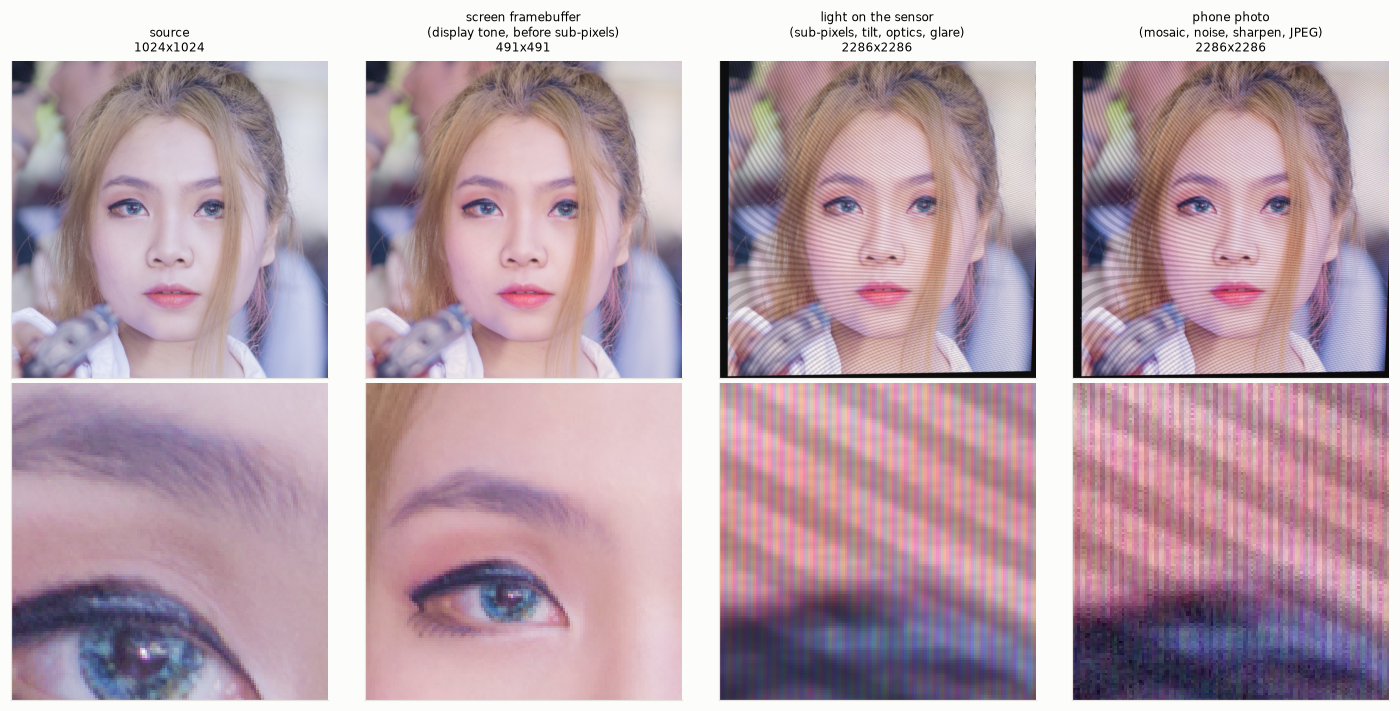

{'layout': 'bgr_stripe', 'screen_per_src': 0.48, 'cam_per_src': 2.232, 'fill': 0.854, 'display_gamma': 2.228, 'saturation': 1.277, 'white_point': (1.1157714242448353, 1.0, 0.895194484815367), 'black_level': 0.001, 'veil': 0.005, 'glare': 0.0, 'glare_xy': (0.8431070419421323, 0.5059752810585223), 'glare_sigma': 0.273, 'dust': 28, 'tilt': 0.034, 'rotation': 0.005, 'blur': 1.408, 'vignette': 0.058, 'camera_exposure': 0.821, 'camera_wb': (1.0183643657096115, 1.0, 1.0487031061691927), 'camera_shot': 0.0, 'camera_read': 0.0, 'camera_demosaic': 137, 'camera_denoise': 0.0, 'camera_contrast': 0.369, 'camera_sharpen_amount': 1.063, 'camera_sharpen_radius': 1.022, 'camera_jpeg_quality': 91}


In [7]:
train_ids = splits[(splits.split == "train") & (splits.label == 0)].id.values
iid = train_ids[0]
src = np.asarray(load_image(ROOT / f"Bonafide/{iid}.png"))
rng = np.random.default_rng([SEED, 99])
p = RecaptureParams.sample(rng, RANGES)
fb = _display(src, p)
light = render_screen(src, p, rng)
photo = camera(light, p.camera, rng)
stages = [("source", src), ("screen framebuffer\n(display tone, before sub-pixels)", (linear_to_srgb(fb) * 255).astype(np.uint8)),
          ("light on the sensor\n(sub-pixels, tilt, optics, glare)", (linear_to_srgb(light / max(np.percentile(light, 99), 1e-6)) * 255).astype(np.uint8)),
          ("phone photo\n(mosaic, noise, sharpen, JPEG)", photo)]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for k, (name, im) in enumerate(stages):
    axes[0, k].imshow(im); axes[0, k].set_title(f"{name}\n{im.shape[1]}x{im.shape[0]}", fontsize=8)
    cy, cx = int(im.shape[0] * 0.42), int(im.shape[1] * 0.4)
    axes[1, k].imshow(im[cy - 64:cy + 64, cx - 64:cx + 64], interpolation="nearest")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in p.to_dict().items()})

## 6. Simulated against real dev attacks

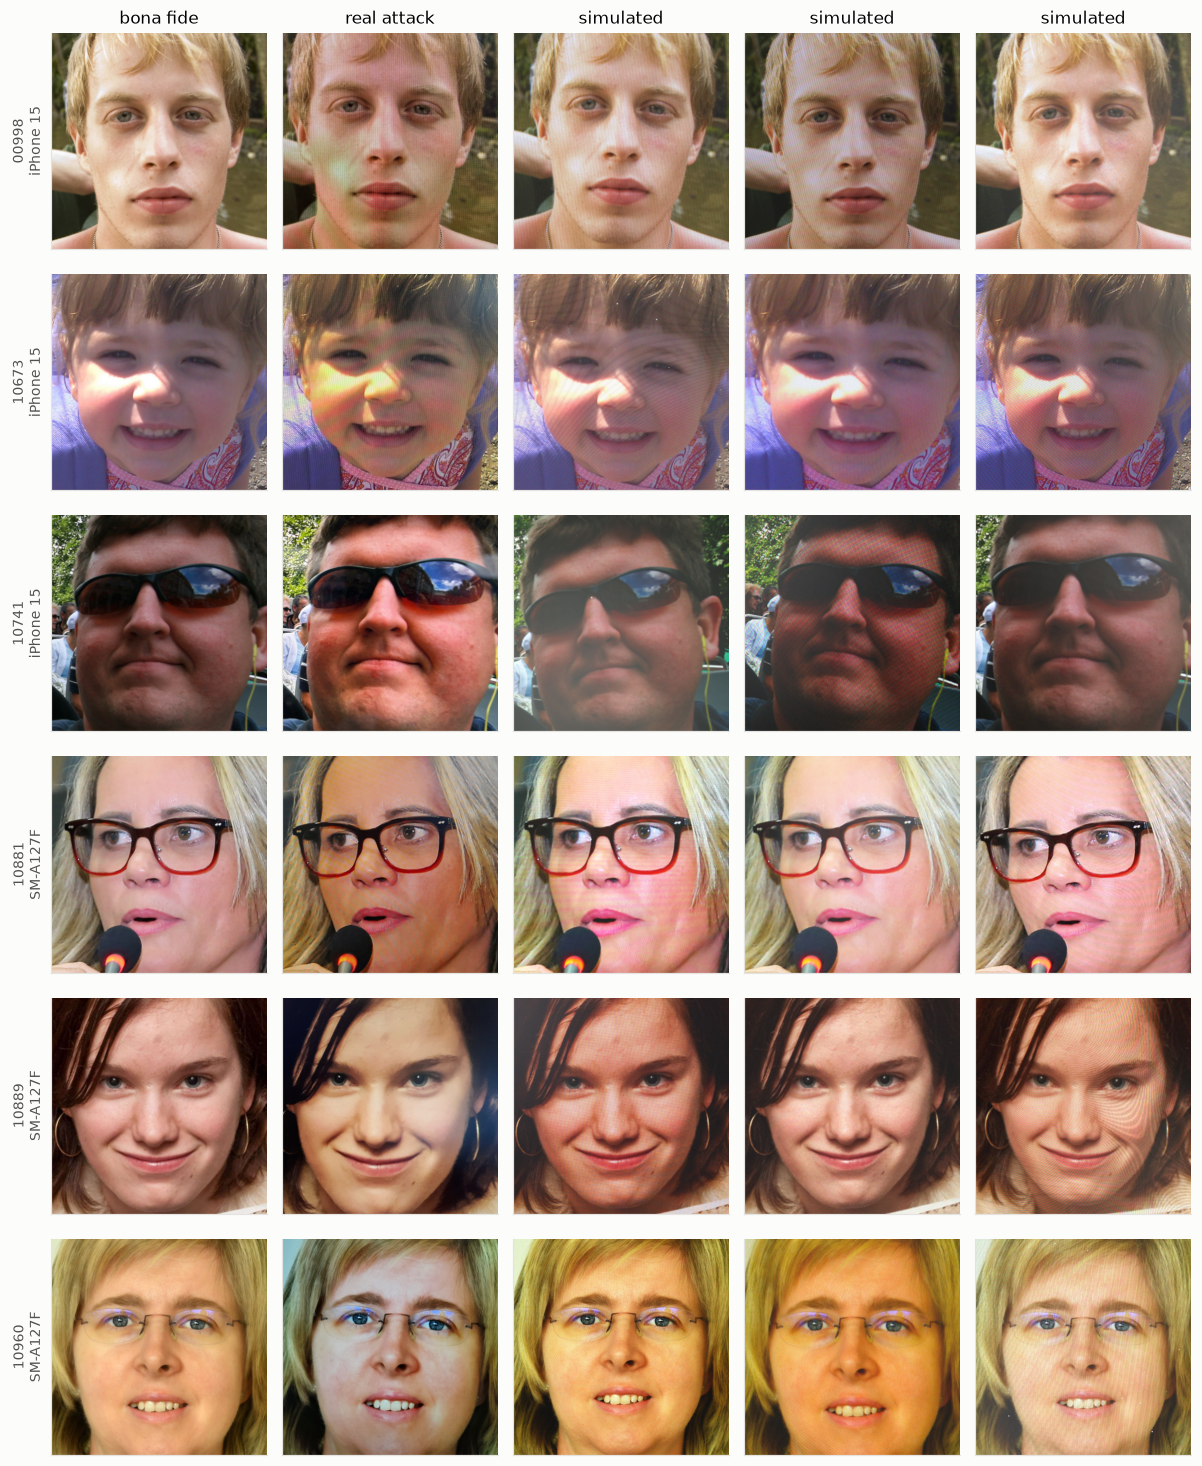

In [8]:
syn = load_cache(Path(cfg.data.cache_dir) / "synth_tight_384_dev.npz")
fs = cache_frame(syn)
fig, axes = plt.subplots(6, 5, figsize=(11, 13.5))
for r, i in enumerate(DEV_IDS):
    ims = [real["images"][(fr.id == i) & (fr.label == 0)][0], real["images"][(fr.id == i) & (fr.label == 1)][0]]
    ims += list(syn["images"][(fs.id == i) & (fs.kind == "synthetic_attack")][:3])
    for c, im in enumerate(ims):
        axes[r, c].imshow(im); axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title(["bona fide", "real attack", "simulated", "simulated", "simulated"][c])
    axes[r, 0].set_ylabel(f"{i}\n{phone[i]}")
plt.tight_layout(); plt.show()

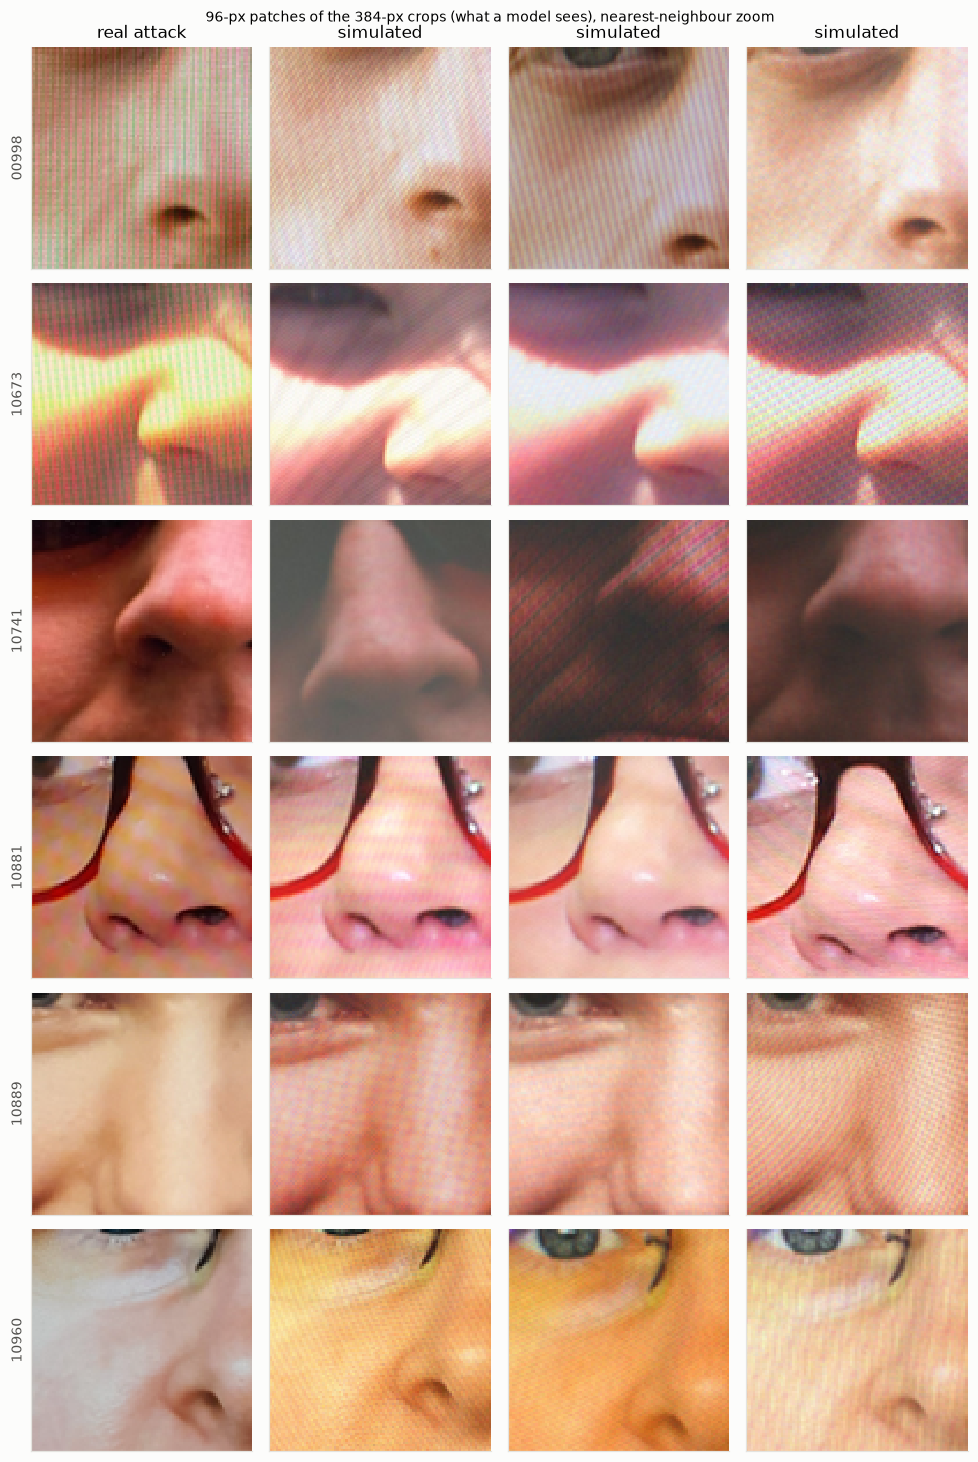

In [9]:
fig, axes = plt.subplots(6, 4, figsize=(9, 13.5))
for r, i in enumerate(DEV_IDS):
    ims = [real["images"][(fr.id == i) & (fr.label == 1)][0]] + list(syn["images"][(fs.id == i) & (fs.kind == "synthetic_attack")][:3])
    for c, im in enumerate(ims):
        axes[r, c].imshow(im[150:246, 100:196], interpolation="nearest"); axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title(["real attack", "simulated", "simulated", "simulated"][c])
    axes[r, 0].set_ylabel(i)
fig.suptitle("96-px patches of the 384-px crops (what a model sees), nearest-neighbour zoom", fontsize=9)
plt.tight_layout(); plt.show()

### Statistics: real, simulated and camera-only

In [10]:
s_cam = (fs.kind == "camera_only").values
idx_b = [np.flatnonzero((fr.id == i) & (fr.label == 0))[0] for i in DEV_IDS]
idx_a = [np.flatnonzero((fr.id == i) & (fr.label == 1))[0] for i in DEV_IDS]
s_syn = (fs.kind == "synthetic_attack").values
groups = {
    "bona fide": (real["images"][idx_b], DEV_IDS, fr.info_resample_ratio.values[idx_b]),
    "camera only": (syn["images"][s_cam], list(fs.id[s_cam]), fs.info_resample_ratio.values[s_cam]),
    "real attack": (real["images"][idx_a], DEV_IDS, fr.info_resample_ratio.values[idx_a]),
    "simulated attack": (syn["images"][s_syn], list(fs.id[s_syn]), fs.info_resample_ratio.values[s_syn]),
}
frames = []
for g, (ims, ids, ratio) in groups.items():
    f = pixel_stats_frame(ims); f["group"], f["id"], f["crop downsample"] = g, ids, ratio
    frames.append(f)
st = pd.concat(frames, ignore_index=True)
COLS = ["brightness", "contrast", "saturation", "sharpness", "noise_sigma", "hf_ratio", "peak_score", "crop downsample"]
display(st.groupby("group")[COLS].median().T.round(3))

group,bona fide,camera only,real attack,simulated attack
brightness,52.558,53.161,47.716,49.084
contrast,18.063,19.923,18.698,17.979
saturation,0.384,0.436,0.415,0.331
sharpness,2.213,2.550,2.510,2.279
noise_sigma,1.449,1.984,1.784,2.922
hf_ratio,0.009,0.016,0.019,0.024
peak_score,1.483,1.417,1.603,2.375
crop downsample,1.841,4.179,4.839,4.161


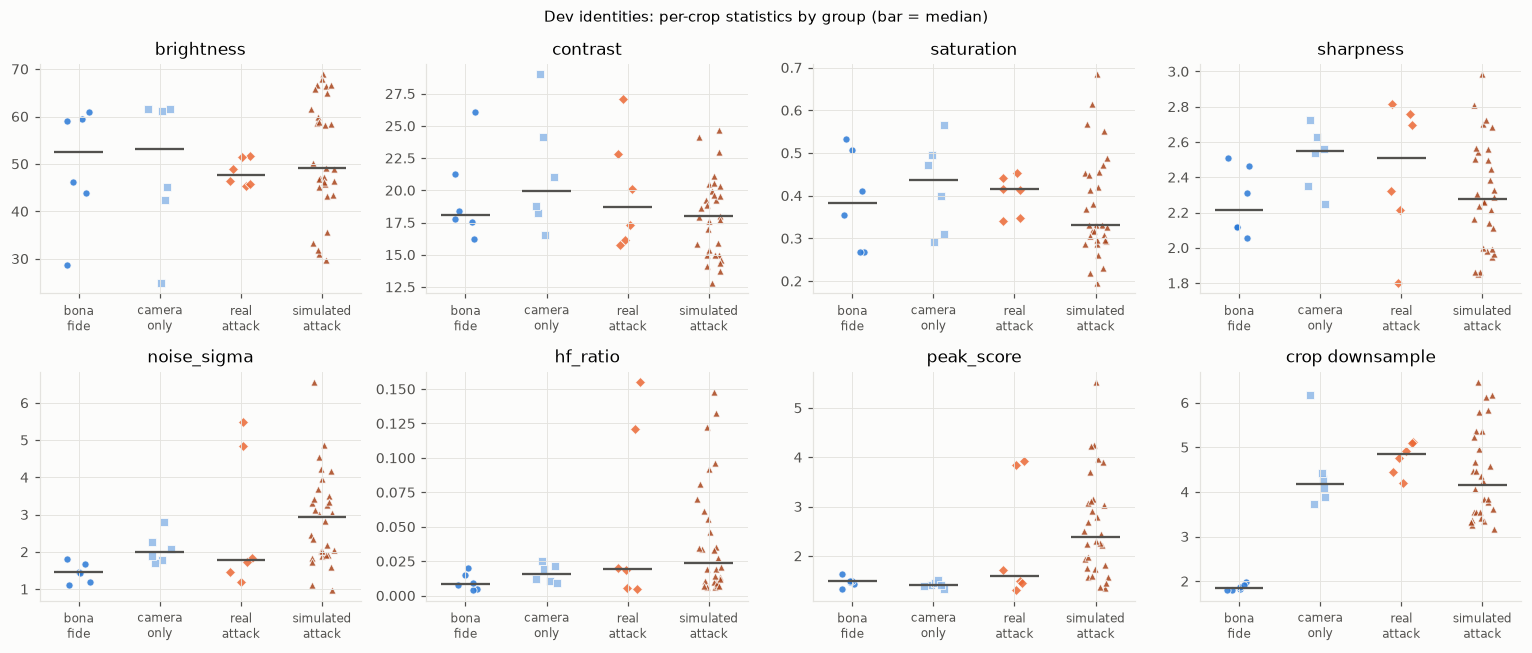

In [11]:
COLORS = {"bona fide": BONAFIDE_C, "camera only": CAMONLY_C, "real attack": ATTACK_C, "simulated attack": SYNTH_C}
MARKERS = {"bona fide": "o", "camera only": "s", "real attack": "D", "simulated attack": "^"}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
rng_j = np.random.default_rng(0)
for ax, col in zip(axes.ravel(), COLS):
    for k, g in enumerate(COLORS):
        v = st.loc[st.group == g, col].values
        ax.scatter(k + rng_j.uniform(-0.15, 0.15, len(v)), v, s=22, color=COLORS[g], marker=MARKERS[g], alpha=0.85, edgecolor=SURFACE, linewidth=0.6)
        ax.hlines(np.median(v), k - 0.3, k + 0.3, color=INK_2, lw=1.5)
    ax.set_xticks(range(4)); ax.set_xticklabels([g.replace(" ", "\n") for g in COLORS], fontsize=8); ax.set_title(col)
fig.suptitle("Dev identities: per-crop statistics by group (bar = median)", fontsize=10)
plt.tight_layout(); plt.show()

In [12]:
b = st[st.group == "bona fide"].set_index("id")
shift_cols = ["brightness", "contrast", "saturation", "sharpness", "noise_sigma", "hf_ratio", "peak_score"]
rows = {}
for g in ("camera only", "real attack", "simulated attack"):
    x = st[st.group == g]
    d = x[shift_cols].values - b.loc[x["id"], shift_cols].values
    rows[g + ": median shift"] = np.median(d, 0)
    rows[g + ": fraction up"] = (d > 0).mean(0)
display(pd.DataFrame(rows, index=shift_cols).T.round(3))

,brightness,contrast,saturation,sharpness,noise_sigma,hf_ratio,peak_score
camera only: median shift,0.841,2.325,0.036,0.224,0.606,0.006,-0.042
camera only: fraction up,0.667,0.833,0.833,1.000,1.000,1.000,0.167
real attack: median shift,-3.743,0.238,0.051,0.206,0.355,0.003,0.199
real attack: fraction up,0.500,0.500,0.667,0.833,0.833,0.833,0.667
simulated attack: median shift,2.255,-1.862,-0.022,0.010,1.420,0.009,0.892
simulated attack: fraction up,0.633,0.200,0.433,0.500,0.900,0.800,0.967


## 7. Resample-ratio shortcut

Camera-only controls use the attacks' camera scale (`cam_per_src` 1.5-3.5), so bona fide crops are downsampled as hard as attacks.

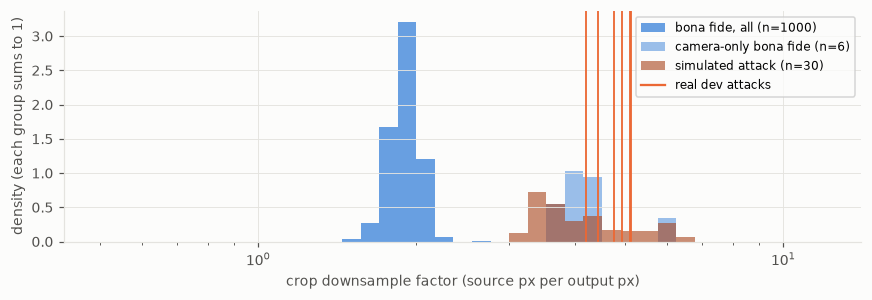

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bins = np.geomspace(0.5, 12, 40)
all_b = fr.info_resample_ratio[fr.label == 0]
ax.hist(all_b, bins=bins, density=True, color=BONAFIDE_C, alpha=0.7, label=f"bona fide, all (n={len(all_b)})")
ax.hist(groups["camera only"][2], bins=bins, density=True, color=CAMONLY_C, alpha=0.9, label=f"camera-only bona fide (n={s_cam.sum()})")
ax.hist(groups["simulated attack"][2], bins=bins, density=True, color=SYNTH_C, alpha=0.6, label=f"simulated attack (n={s_syn.sum()})")
for v in groups["real attack"][2]:
    ax.axvline(v, color=ATTACK_C, lw=1.2)
ax.plot([], [], color=ATTACK_C, label="real dev attacks")
ax.set_xscale("log"); ax.set_xlabel("crop downsample factor (source px per output px)"); ax.set_ylabel("density (each group sums to 1)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Summary

- The grid is the main cue at native resolution and mostly gone after cropping.
- Tone and colour shift in no consistent direction.
- The camera-only control raises sharpness, noise and high-frequency energy too, so those are not screen evidence.
- Gaps left on purpose: stronger peaks, more noise, lower saturation and smaller sharpness gains than real.
- Not modelled: refresh banding, occlusion, curved screens, HDR, video compression.